# Evaluating Classification

*Interpret confusion matrices, accuracy, precision, recall, and F1 through message filtering.*

## Evaluation Targets and Criteria

- Classification performance is evaluated by comparing actual and predicted labels. Counting only total errors hides which classes were misclassified.
- The inbox contains a fixed set of 20 spam and 80 legitimate messages. Spam is the positive class, and legitimate is the negative class.
- Messages predicted as spam are filtered; messages predicted as legitimate are kept. Combining actual classes with these predictions gives four outcomes.

## Confusion Matrices and Error Types

- A true positive (TP) is spam that was caught.
- A false positive (FP) is a legitimate message that was incorrectly filtered.
- A false negative (FN) is spam that was missed.
- A true negative (TN) is a legitimate message that was correctly kept.
- A confusion matrix summarizes the counts of these four outcomes. This figure places actual classes in rows and predicted classes in columns.

<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-bigdata/main/11-1_Classification/assets/05_confusion_matrix.png" alt="Confusion matrix for message classification" width="512">

- Because the actual spam and legitimate totals are fixed, the remaining counts are:

  $\displaystyle FN=20-TP, \qquad TN=80-FP.$


## Error Types and Evaluation Metrics

### Accuracy

- Accuracy is the fraction of all messages classified correctly. It includes both caught spam and correctly kept legitimate messages.

  $\displaystyle \mathrm{Accuracy}=\frac{TP+TN}{100}.$

- Predicting every message as legitimate gives 80% accuracy because legitimate messages are the majority. However, it catches no spam, so error types must be evaluated separately.

### Precision and Recall

- Precision is the fraction of filtered messages that are actually spam. Recall is the fraction of actual spam that was caught.

  $\displaystyle \mathrm{Precision}=\frac{TP}{TP+FP}, \qquad \mathrm{Recall}=\frac{TP}{TP+FN}=\frac{TP}{20}.$

- Filtering every message gives 100% recall but only 20% precision, because most filtered messages are legitimate.
- Keeping every message leaves no predicted positives, so precision is undefined. Recall is 0 because no actual spam is caught.

### F1

- F1 is the harmonic mean of precision and recall. It does not give a high score when only one of the two is high.

  $\displaystyle F_1=\frac{2TP}{2TP+FP+FN}.$

- False alarms and missed spam appear in the denominator, but true negatives do not. F1 alone cannot fully evaluate performance on legitimate messages.
- In this inbox, catching no spam gives $TP=0$ and therefore F1=0.

## How Error Counts Change Metrics

- "Spam caught (TP)" and "False alarms (FP)" are the numbers of caught spam and incorrectly filtered legitimate messages. Predictions are constructed directly to compare the two errors' effects; no model is trained.
- Holding FP fixed while increasing TP increases recall. When false alarms are present, precision also increases.
- Holding TP fixed while increasing FP increases only the denominator of precision. When TP is positive, precision decreases; recall stays unchanged.
- "Keep all" keeps every message, and "Filter all" filters every message. "Perfect" sets $TP=20$, $FP=0$, making all four metrics 100%.
- Each square represents one message, and × marks a filtered message. In the matrix, "Keep" means a legitimate prediction and "Filter" means a spam prediction. The squares and matrix show the same predictions.


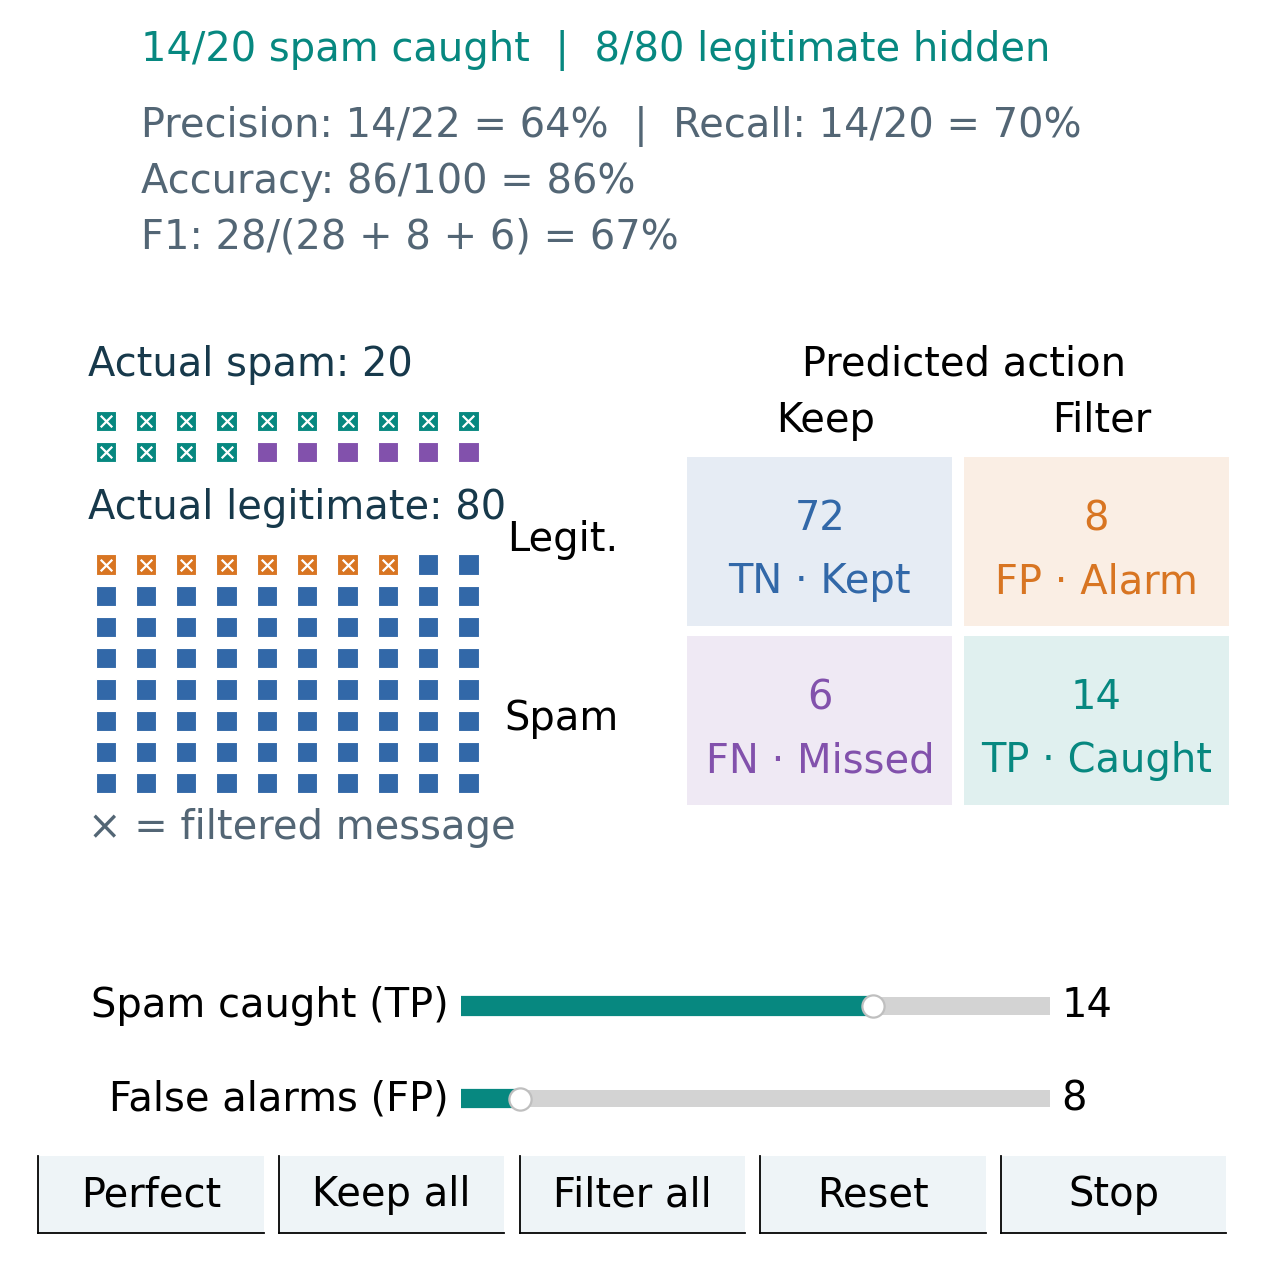

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 18, "axes.labelsize": 18,
    "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=64)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=18, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=18, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 2.22 / height
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(18)
            slider.valtext.set_fontsize(18)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .94 / len(commands) - .012)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.03 + i * (width + .012), .25 / height, width, .48 / height]),
                            label,
                            color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(18)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        lower = ((self.tree_ax.get_position().y0 - .02) * height
                 if hasattr(self, "tree_ax") else max(0, self.ax.get_position().y0 * height - .78))
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=64, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="512px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "180px"},
                                  layout=Layout(width="100%", max_width="512px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="512px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=512,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()


def make_messages(seed, count=240, spam_fraction=.35):
    rng = np.random.default_rng(seed)
    labels = np.zeros(count, dtype=int)
    labels[:round(count * spam_fraction)] = 1
    rng.shuffle(labels)
    phrases = rng.binomial(10, np.where(labels == 1, .53, .13))
    links = rng.binomial(4, np.where(labels == 1, .57, .13))
    return np.column_stack([phrases, links]), labels


def make_fruit(seed):
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), 60)
    centers = np.array([[8, 1.15], [30, 1.05], [53, 2.8]])
    spreads = np.array([[8, .18], [7, .16], [7, .5]])
    values = centers[labels] + rng.normal(size=(len(labels), 2)) * spreads[labels]
    return np.clip(values, [0, .7], [70, 4.2]), labels

actual_spam = 20
actual_legitimate = 80
observed = np.r_[np.ones(actual_spam, dtype=int), np.zeros(actual_legitimate, dtype=int)]


def render_messages(view, caught, false_alarms):
    caught, false_alarms = int(caught), int(false_alarms)
    predicted = np.zeros(len(observed), dtype=int)
    predicted[:caught] = 1
    predicted[actual_spam:actual_spam + false_alarms] = 1
    result = classification_metrics(observed, predicted)
    matrix = np.array([[result["TN"], result["FP"]], [result["FN"], result["TP"]]])
    tp, fp, fn, tn = (result[name] for name in ["TP", "FP", "FN", "TN"])
    filtered = tp + fp
    ax = view.ax
    position = ax.get_position()
    ax.set_position([.06, position.y0, .90, position.height])
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.axis("off")
    ax.text(.01, .96, "Actual spam: 20", fontsize=18, color="#17394b")
    ax.text(.01, .68, "Actual legitimate: 80", fontsize=18, color="#17394b")
    message_index = np.arange(len(observed))
    group_index = np.where(observed == 1, message_index, message_index - actual_spam)
    x = .025 + (group_index % 10) * .035
    y = np.where(observed == 1, .87, .59) - (group_index // 10) * .061
    colors = np.where(observed == 1, np.where(predicted == 1, TEAL, PURPLE),
                      np.where(predicted == 1, ORANGE, BLUE))
    ax.scatter(x, y, marker="s", s=82, c=colors, edgecolor="white", linewidth=.5)
    hidden = predicted == 1
    ax.scatter(x[hidden], y[hidden], marker="x", s=27, color="white", linewidth=1)
    ax.text(.01, .055, "× = filtered message", fontsize=18, color="#536675")
    ax.text(.77, .96, "Predicted action", ha="center", fontsize=18)
    ax.text(.65, .85, "Keep", ha="center", fontsize=18)
    ax.text(.89, .85, "Filter", ha="center", fontsize=18)
    ax.text(.47, .64, "Legit.", ha="right", va="center", fontsize=18)
    ax.text(.47, .29, "Spam", ha="right", va="center", fontsize=18)
    cells = [(0, 0, tn, "TN · Kept", BLUE), (0, 1, fp, "FP · Alarm", ORANGE),
             (1, 0, fn, "FN · Missed", PURPLE), (1, 1, tp, "TP · Caught", TEAL)]
    from matplotlib.patches import Rectangle
    for row, col, count, label, color in cells:
        x = .53 + col * .24
        y = .47 - row * .35
        ax.add_patch(Rectangle((x, y), .23, .33, facecolor=color, alpha=.12, edgecolor="none"))
        ax.text(x + .115, y + .21, str(count), ha="center", va="center", fontsize=18, color=color)
        ax.text(x + .115, y + .065, label, ha="center", fontsize=18, color=color)
    view.status.set_text(f"{tp}/20 spam caught  |  {fp}/80 legitimate hidden")
    precision = f"{tp}/{filtered} = {percent(result['precision'])}" if filtered else "0/0 → undefined"
    view.detail.set_text(
        f"Precision: {precision}  |  Recall: {tp}/20 = {percent(result['recall'])}\n"
        f"Accuracy: {tp + tn}/100 = {percent(result['accuracy'])}\n"
        f"F1: {2 * tp}/({2 * tp} + {fp} + {fn}) = {percent(result['F1'])}")
    return {"prediction": predicted, "observed": observed.copy(), "metrics": result,
            "matrix": matrix, "filtered": filtered}


spam_demo = ClassificationExplorer("spam", render_messages, [
    ("caught", "Spam caught (TP)", 0, actual_spam, 14, 1, "%0.0f"),
    ("false_alarms", "False alarms (FP)", 0, actual_legitimate, 8, 1, "%0.0f"),
], actions=[
    ("Perfect", lambda view: view.set_values(caught=20, false_alarms=0)),
    ("Keep all", lambda view: view.set_values(caught=0, false_alarms=0)),
    ("Filter all", lambda view: view.set_values(caught=20, false_alarms=80)),
])
spam_demo.start()


## Evaluation Conditions and Interpretation

### Class Decisions and Predicted Probabilities

- A real filter cannot choose TP and FP independently. Lowering its probability threshold can catch more spam but can also increase false alarms.
- Identical class decisions can come from different predicted probabilities, so a confusion matrix alone cannot establish whether probabilities are appropriate.
- Probability calibration adjusts predicted probabilities to match observed frequencies. In a well-calibrated model, about 80% of messages assigned spam probabilities near 80% are actually spam.

### Generalization and Error Costs

- The displayed scores come from directly constructed predictions. For a real model, select settings using validation data, then evaluate on test data excluded from training and setting selection.
- The choice of metric depends on the cost of blocking legitimate messages and the cost of missing spam. No single metric represents every error cost.

## Takeaway

Accuracy summarizes overall correctness, while precision and recall distinguish false alarms from missed positives. Choose metrics that reflect the consequences of each error type.
